# Experiment 02 — PdO on Al₂O₃ / sapphire: replicate noise, ANOVA and a three-objective GP

The 14 usable Sobol conditions now carry three responses on the same films: **Hall mobility**, **carrier concentration**
(May delivery) and the **XRD crystallinity index** (27 Aug delivery, `utils/xrd_crystallinity.py`). This notebook

1. merges the three responses film by film,
2. flags outlying replicates with the rule used earlier in this repository (Cook's distance > 4/n),
3. tabulates the **mean and coefficient of variation** per condition, with and without those outliers,
4. runs the **ANOVA** — between conditions and per factor — reporting **F and p**,
5. fits a **three-output Gaussian process** to the condition means and checks it by leave-one-out,
6. shows what the current data state implies for new samples: the GP's predictions at the planned Experiment 04 recipes
   and the points a Bayesian-optimisation step (qLogNEHVI) would propose next.

Nothing is written to disk unless `SAVE_OUTPUTS = True` in the setup cell.

In [1]:
import os, sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.outliers_influence import OLSInfluence
from scipy import stats
import torch
warnings.filterwarnings('ignore')

REPO_ROOT = '/data/zhq7531/IDEAL/DMREF/repository_dmref'
os.chdir(REPO_ROOT)
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)
from utils import xrd_crystallinity as xc
from utils import mobo

XLSX = 'raw_data_received/pdo/08_27_26/PdO_data_0827.xlsx'                       # XRD (sobol sheet)
RUN_TABLE = 'Processed_data_inputs/pdo/experiment02/raw_data_update_05_22_2026.xlsx'  # design factors
HALL = 'Processed_data_inputs/pdo/experiment02/Raw_update_05_22_2026.txt'            # Hall per film, incl. contact fails
DESIGN04 = 'output/pdo/experiment04_si_stacks_doe/PdO_SiStacks_sliced_design.xlsx'    # planned Si-stack recipes
GLOBAL_SEED = 20

# ---- saving: nothing is written unless SAVE_OUTPUTS is True ----
SAVE_OUTPUTS = False
OUT_DIR = 'output/pdo/experiment02_anova_cv_gp'
OUT_FILES = {                      # set an entry to None to skip it
    'design_corr_table':  'design_factor_correlations.xlsx',
    'design_corr_fig':    'design_factor_correlations.png',
    'failure_map_fig':    'contact_failures_ox_vs_anneal.png',
    'cryst_ref_table':    'crystallinity_reference_best_recipe.xlsx',
    'cryst_ref_fig':      'crystallinity_reference_best_recipe.png',
    'outliers_table':     'outliers_cooks_distance.xlsx',
    'iqr_table':          'outliers_iqr.xlsx',
    'iqr_fig':            'outliers_iqr.png',
    'iqr_within_fig':     'iqr_within_recipe.png',
    'iqr_sim_fig':        'iqr_small_sample_simulation.png',
    'cv_table':           'cv_per_condition.xlsx',
    'anova_between':      'anova_between_conditions.xlsx',
    'anova_per_factor':   'anova_per_factor.xlsx',
    'gp_loo_table':       'gp_loo_metrics.xlsx',
    'gp_loo_fig':         'gp_loo_parity.png',
    'bo_proposals':       'bo_proposals.xlsx',
    'new_points_fig':     'new_points_objective_space.png',
}
def save(key, obj):
    name = OUT_FILES.get(key)
    if not SAVE_OUTPUTS or name is None:
        return
    os.makedirs(OUT_DIR, exist_ok=True); path = os.path.join(OUT_DIR, name)
    obj.savefig(path, dpi=170, bbox_inches='tight') if hasattr(obj, 'savefig') else obj.to_excel(path, index=False)
    print('saved', path)

BLUE, ORANGE, AQUA, MUTED, INK, INK2, RED = '#2a78d6', '#eb6834', '#1baf7a', '#898781', '#1b2a3a', '#52514e', '#d03b3b'
plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': 'white', 'axes.edgecolor': '#c3c2b7', 'axes.grid': True,
                     'grid.color': '#e1e0d9', 'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
                     'text.color': INK, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'legend.frameon': False})
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
print('SAVE_OUTPUTS =', SAVE_OUTPUTS)

SAVE_OUTPUTS = False


## 1. Data: three responses on the same films

The XRD pipeline gives the crystallinity index for the 42 scanned films; the May Hall file gives mobility and carrier
concentration for the 41 films that did not contact-fail (02_14 was scanned but failed in Hall). Carrier concentration is
analysed on a log₁₀ scale, as in the earlier Experiment 02 notebook, because it spans more than a decade.

In [2]:
xrd = xc.analyze_sheet(XLSX, 'sobol', verbose=False)
xrd = xc.attach_run_table(xrd, RUN_TABLE)
xrd, refs = xc.add_crystallinity(xrd)

hall = pd.read_csv(HALL, sep='\t'); hall = hall.rename(columns={hall.columns[0]: 'run'})
hall['mobility'] = pd.to_numeric(hall['Hall mobility (cm^2/V*s)'], errors='coerce')
hall['carrier'] = pd.to_numeric(hall['Carrier concentration (#/cm^3)'], errors='coerce')
hall['sample'] = hall.Replicate.map(lambda r: f'{r:02d}') + '_' + hall.run.map(lambda r: f'{r:02d}')

FACTORS = xc.FACTOR_COLS
data = xrd[['sample', 'run', 'replicate'] + FACTORS + ['thickness_final_nm', 'crystallinity_pct', 'peak_detected']].merge(
    hall[['sample', 'mobility', 'carrier']], on='sample', how='left')
data['log10_carrier'] = np.log10(data['carrier'])
RESP = {'mobility': 'Hall mobility (cm²/V·s)', 'log10_carrier': 'log₁₀ carrier (cm⁻³)', 'crystallinity_pct': 'Crystallinity index (%)'}
print(f"{len(data)} films, {data.run.nunique()} conditions | mobility {data.mobility.notna().sum()} | carrier {data.carrier.notna().sum()} | crystallinity {data.crystallinity_pct.notna().sum()}")
data.head()

42 films, 14 conditions | mobility 41 | carrier 41 | crystallinity 42


,sample,run,replicate,Dep Power (W),O2 Flow (sccm),Dep Press (mTorr),Dep Temp (°C),Ox Temp (°C),Ox Press (atm),Ox Time (min),Vac Ann Temp (°C),Vac Ann Time (min),Dep Thickness (nm),thickness_final_nm,crystallinity_pct,peak_detected,mobility,carrier,log10_carrier
0,01_02,2,1,28,11.5,9.7,25,476.8,0.02,14.3,155.4,18.1,5.1,8.500000,20.678110,False,4.36,1.740000e+20,20.240549
1,01_03,3,1,40,9.1,3.4,425,262.5,0.02,71.7,400.0,57.9,2.2,3.666667,19.220661,False,3.89,1.960000e+20,20.292256
2,01_05,5,1,19,7.0,8.5,25,661.6,1.00,82.5,288.6,31.0,3.5,5.833333,9.809617,False,1.91,5.610000e+19,19.748963
3,01_07,7,1,23,1.6,7.3,25,364.3,0.02,118.0,474.1,117.0,8.6,14.333333,54.253421,True,7.25,5.660000e+19,19.752816
4,01_08,8,1,8,14.2,2.6,425,594.5,1.00,26.1,48.9,14.6,1.7,2.833333,15.929081,False,1.70,1.190000e+20,20.075547


### 1b. The design behind the data: factor correlations

A good space-filling design keeps the inputs uncorrelated, so that the effect of each factor can be separated from the
others; the campaign guard is |r| < 0.3. The heatmaps show the Pearson correlation between the 10 factors for the
**23 recipes as designed** (scrambled Sobol, seed 20) and for the **14 recipes that gave data**. As a yardstick, the table
gives the typical maximum |r| of other generators at the same size (23 points, 10 factors, two of them two-level).

In [3]:
SHORT = {'Dep Power (W)': 'Power', 'O2 Flow (sccm)': 'O₂ flow', 'Dep Press (mTorr)': 'Dep press', 'Dep Temp (°C)': 'Dep temp',
         'Ox Temp (°C)': 'Ox temp', 'Ox Press (atm)': 'Ox press', 'Ox Time (min)': 'Ox time', 'Vac Ann Temp (°C)': 'Ann temp',
         'Vac Ann Time (min)': 'Ann time', 'Dep Thickness (nm)': 'Thickness'}
design23 = pd.read_excel(RUN_TABLE).drop_duplicates('Base_Run_ID').set_index('Base_Run_ID')[FACTORS]
measured14 = design23.loc[sorted(data.run.unique())]
corr = {'designed (23 recipes)': design23.corr(), f'measured ({len(measured14)} recipes)': measured14.corr()}

def corr_summary(C):
    off = C.where(~np.eye(len(C), dtype=bool)).stack()
    off = off[[a < b for a, b in off.index]]
    top = off.abs().idxmax()
    return dict(max_abs_r=off.abs().max(), pair=f'{SHORT[top[0]]} × {SHORT[top[1]]}', mean_abs_r=off.abs().mean(), pairs_above_0_3=int((off.abs() > 0.3).sum()))
design_corr = pd.DataFrame({k: corr_summary(C) for k, C in corr.items()}).T
save('design_corr_table', design_corr.reset_index())

# yardstick: typical max |r| of other generators at n = 23 (two-level factors snapped)
from scipy.stats import qmc
def max_r(U):
    U = U.copy(); U[:, [FACTORS.index('Dep Temp (°C)'), FACTORS.index('Ox Press (atm)')]] = (U[:, [3, 5]] >= 0.5)
    C = np.corrcoef(U.T); np.fill_diagonal(C, 0); return np.abs(C).max()
gens = {'random uniform': lambda s: np.random.default_rng(s).random((23, 10)),
        'plain LHS': lambda s: qmc.LatinHypercube(d=10, seed=s).random(23),
        'scrambled Sobol (this design type)': lambda s: qmc.Sobol(d=10, scramble=True, seed=s).random(23),
        'optimised LHS': lambda s: qmc.LatinHypercube(d=10, optimization='random-cd', seed=s).random(23)}
yard = pd.DataFrame({k: [np.median([max_r(g(s)) for s in range(60)])] for k, g in gens.items()}, index=['median max |r|, 23 points']).T
rng_sub = np.random.default_rng(0); D = design23.to_numpy(float)
sub_vals = [np.abs(np.corrcoef(D[rng_sub.choice(23, len(measured14), replace=False)].T) - np.eye(10)).max() for _ in range(3000)]
print(f'Random {len(measured14)}-of-23 subsets of this design: median max |r| {np.median(sub_vals):.2f}, '
      f'{100 * np.mean(np.array(sub_vals) >= design_corr.iloc[1].max_abs_r):.1f} % reach the measured {design_corr.iloc[1].max_abs_r:.2f}')
display(design_corr.style.format({'max_abs_r': '{:.2f}', 'mean_abs_r': '{:.2f}'}))
yard.round(2)

Random 14-of-23 subsets of this design: median max |r| 0.60, 0.1 % reach the measured 0.90


,max_abs_r,pair,mean_abs_r,pairs_above_0_3
designed (23 recipes),0.52,Ox time × Ann time,0.15,4
measured (14 recipes),0.90,O₂ flow × Ann temp,0.20,10


,"median max |r|, 23 points"
random uniform,0.51
plain LHS,0.52
scrambled Sobol (this design type),0.48
optimised LHS,0.21


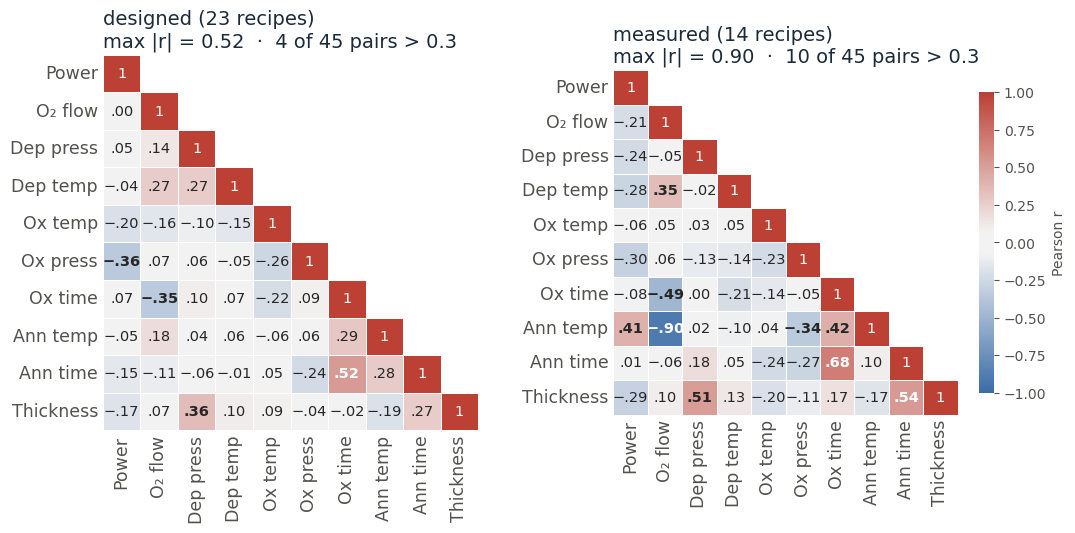

In [4]:
import seaborn as sns
CMAP = sns.diverging_palette(250, 15, s=75, l=45, sep=20, as_cmap=True)
fig, axes = plt.subplots(1, 2, figsize=(11.2, 5.3))
for ax, (title_, C_mat) in zip(axes, corr.items()):
    Cs = C_mat.rename(index=SHORT, columns=SHORT)
    mask = np.triu(np.ones_like(Cs, dtype=bool), k=1)                         # lower triangle + diagonal only
    annot = Cs.map(lambda v: '1' if abs(v) >= 0.995 else ('.00' if round(v, 2) == 0 else f'{v:.2f}'.replace('-0.', '−.').replace('0.', '.')))
    sns.heatmap(Cs, mask=mask, vmin=-1, vmax=1, center=0, cmap=CMAP, annot=annot, fmt='', annot_kws={'size': 10.5},
                cbar=ax is axes[-1], cbar_kws={'shrink': 0.8, 'label': 'Pearson r'}, linewidths=0.6, linecolor='white', square=True, ax=ax)
    s_ = design_corr.loc[title_]
    ax.set_title(f'{title_}\nmax |r| = {s_.max_abs_r:.2f}  ·  {s_.pairs_above_0_3} of 45 pairs > 0.3', fontsize=14, color=INK, loc='left')
    ax.tick_params(labelsize=12.5, length=0); ax.grid(False)
    for t in ax.texts:                                                         # bold the pairs above the 0.3 guard
        try:
            if abs(float(t.get_text().replace('−', '-'))) > 0.3 and t.get_text() != '1': t.set_fontweight('bold')
        except ValueError:
            pass
fig.tight_layout(); save('design_corr_fig', fig); plt.show()

**Reading 1b.**

* **As designed (23 recipes)**: max |r| = 0.52 (oxidation time × anneal time), 4 of 45 pairs above 0.3, mean |r| = 0.15.
  That is typical of a 23-point scrambled Sobol design (median max |r| 0.48) and no better than random or plain-LHS
  designs of the same size (0.51–0.52); an optimised LHS reaches 0.21. A standard design with reasonable coverage, but
  it does not meet the 0.3 guard.
* **As measured (14 recipes)**: the 9 contact failures were not random — 7 of them were annealed above 540 °C and the other
  two oxidised above 730 °C. Among the survivors the remaining hot-anneal recipes happen to have low O₂ flow, so
  **O₂ flow and anneal temperature correlate at −0.90**; only 0.1 % of random 14-of-23 subsets of this design get that
  high. Oxidation time × anneal time (0.68), thickness × anneal time (0.54) and deposition pressure × thickness (0.51) also rise.
* **Consequence for §4**: the per-factor ANOVA cannot cleanly separate O₂ flow from anneal temperature, nor deposition
  pressure from thickness; a significant result for one of them may belong to the other.
* **For the next batch**: the Si-stack run sheet (sliced optimised LHS) has max |r| 0.24 and 0.21 per stack and 0.11 for
  the two stacks together, and the 300 °C anneal cap should keep failures from removing a whole block of the design.

**Where the 9 failed recipes sit.** The failures are what turned the designed correlations into the measured ones, so
here they are in the plane of the two thermal steps that separate them: oxidation and vacuum-anneal temperature.
Shaded = beyond the hottest setting at which any recipe survived; dashed box = the Experiment 04 limits for the Si stacks.

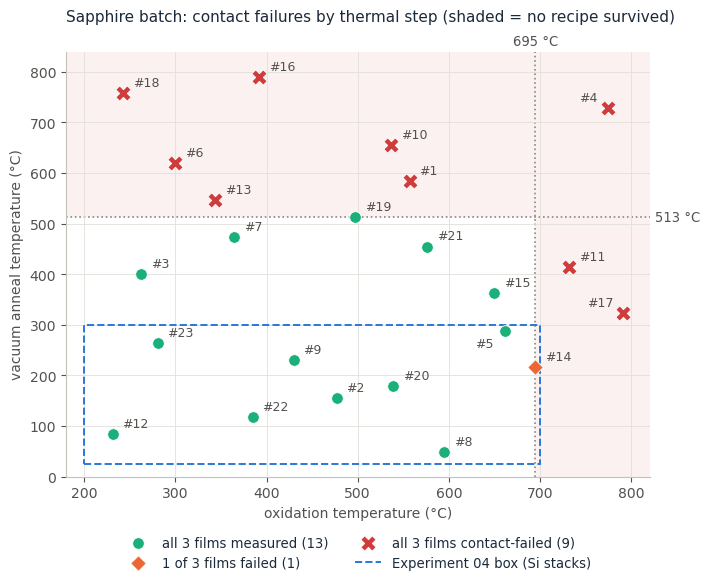

,Ox Temp (°C),Vac Ann Temp (°C),Ox Press (atm),films_failed,status
Base_Run_ID,,,,,
17,791.0,323.0,0.02,3,failed
11,732.0,415.0,0.02,3,failed
13,344.0,546.0,1.00,3,failed
1,557.0,584.0,1.00,3,failed
6,300.0,620.0,0.02,3,failed
10,537.0,655.0,0.02,3,failed
4,774.0,728.0,1.00,3,failed
18,243.0,757.0,1.00,3,failed
16,392.0,790.0,1.00,3,failed


In [5]:
# where the contact failures sit in the oxidation / anneal temperature plane
from matplotlib.patches import Rectangle
hall_fail = hall.assign(fail=hall['Hall mobility (cm^2/V*s)'].astype(str).str.contains('Fail')).groupby('run').fail.sum()
fm = design23[['Ox Temp (°C)', 'Vac Ann Temp (°C)', 'Ox Press (atm)']].join(hall_fail.rename('films_failed'))
fm['status'] = np.select([fm.films_failed == 0, fm.films_failed == 3], ['ok', 'failed'], 'partial')
ok = fm[fm.status != 'failed']
ann_edge, ox_edge = ok['Vac Ann Temp (°C)'].max(), ok['Ox Temp (°C)'].max()   # hottest settings any recipe survived
STYLE = {'ok': ('all 3 films measured', AQUA, 'o', 70), 'partial': ('1 of 3 films failed', ORANGE, 'D', 62),
         'failed': ('all 3 films contact-failed', RED, 'X', 120)}
X0, X1, Y0, Y1 = 180, 820, 0, 840

fig, ax = plt.subplots(figsize=(7.2, 6.0))
ax.add_patch(Rectangle((X0, ann_edge), X1 - X0, Y1 - ann_edge, color=RED, alpha=0.07, lw=0, zorder=0))
ax.add_patch(Rectangle((ox_edge, Y0), X1 - ox_edge, ann_edge - Y0, color=RED, alpha=0.07, lw=0, zorder=0))
ax.axhline(ann_edge, color=MUTED, ls=':', lw=1.2, zorder=1); ax.axvline(ox_edge, color=MUTED, ls=':', lw=1.2, zorder=1)
ax.text(X1 + 6, ann_edge, f'{ann_edge:.0f} °C', color=INK2, fontsize=9.5, va='center', clip_on=False)
ax.text(ox_edge, Y1 + 8, f'{ox_edge:.0f} °C', color=INK2, fontsize=9.5, ha='center', va='bottom', clip_on=False)
ax.add_patch(Rectangle((200, 25), 500, 275, fill=False, ec=BLUE, ls='--', lw=1.4, zorder=2))
for st, (lab, col, mk, sz) in STYLE.items():
    sub = fm[fm.status == st]
    ax.scatter(sub['Ox Temp (°C)'], sub['Vac Ann Temp (°C)'], s=sz, color=col, marker=mk, zorder=4,
               label=f'{lab} ({len(sub)})', edgecolor='white', linewidth=0.6)
OFFSET = {5: (-8, -12, 'right')}                         # keep #5's label off the box edge and away from #14
for r, row in fm.iterrows():
    dx, dy, ha = OFFSET.get(r, (-7, 5, 'right') if row['Ox Temp (°C)'] > 760 else (7, 5, 'left'))
    ax.annotate(f'#{r}', (row['Ox Temp (°C)'], row['Vac Ann Temp (°C)']), xytext=(dx, dy), textcoords='offset points',
                ha=ha, fontsize=9, color=INK2, zorder=5)
ax.plot([], [], color=BLUE, ls='--', lw=1.4, label='Experiment 04 box (Si stacks)')
ax.set_xlim(X0, X1); ax.set_ylim(Y0, Y1)
ax.set_xlabel('oxidation temperature (°C)'); ax.set_ylabel('vacuum anneal temperature (°C)')
ax.set_title('Sapphire batch: contact failures by thermal step (shaded = no recipe survived)', loc='left', fontsize=11, pad=22)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.11), ncol=2, fontsize=9.5)
fig.tight_layout(); save('failure_map_fig', fig); plt.show()
fm.assign(**{'Ox Temp (°C)': fm['Ox Temp (°C)'].round(0), 'Vac Ann Temp (°C)': fm['Vac Ann Temp (°C)'].round(0)}) \
  .sort_values(['status', 'Vac Ann Temp (°C)']).query("status != 'ok'")

**Reading the failure map.**

* **The anneal alone explains 7 of 9 failures**: every recipe annealed above 513 °C (#19, the hottest survivor) failed,
  whatever its oxidation temperature (243–774 °C). The other two, **#11 and #17**, were annealed at only 415 and 323 °C
  but **oxidised at 732 and 791 °C**: no recipe survived oxidation above 695 °C.
* **#14 sits on that edge** (695 °C) and lost one of its three films: 02_14 failed in Hall. It is also the low-crystallinity
  film that Cook's distance flags in §2 (32 % against 85 and 109 % for its replicates), which fits a damaged film rather
  than a measurement fluke.
* **The edges are only bracketed**: between 513 and 546 °C for the anneal, between 695 and 732 °C for oxidation. With 23
  recipes a diagonal "thermal budget" boundary cannot be ruled out (#15 at 649 / 362 °C survived, #11 at 732 / 415 °C did not).
* **For the Si batch**: the Experiment 04 box (anneal ≤ 300 °C) stays 213 °C below the anneal edge, but its 700 °C
  oxidation cap sits right on the edge where #14 already lost a film, and ND expects films on Si to fail at lower
  temperature than on sapphire. That risk was accepted to keep the #14 recipe family inside the box.

### 1c. Alternative reference for the crystallinity index: the best recipe

The index in §1 uses A_ref = the mean area of the **3 strongest films**, which come from different recipes. The
alternative here first averages the replicate films **within each recipe** and takes the **highest recipe mean** as
A_ref, so that 100 % means "as crystalline as the best condition" rather than "as the best single films".
`xc.add_crystallinity(..., ref='best_run')` does this (`ref='run9'` pins a given recipe).

In [6]:
xrd_best, refs_best = xc.add_crystallinity(xrd, ref='best_run')
A_top3, A_best = refs.ref_area.iloc[0], refs_best.ref_area.iloc[0]
top3 = xrd[xrd.peak_detected].nlargest(3, 'auc_101_net')[['sample', 'auc_101_net']]
area_mean = xrd.groupby('run').auc_101_net.mean()
best_run = int(area_mean.idxmax())
print('top-3 films      :', ', '.join(f'{s} {a:.1f}' for s, a in top3.values), f'-> A_ref = {A_top3:.2f}')
print(f'best recipe mean : #{best_run} -> A_ref = {A_best:.2f}   (every index x {A_top3 / A_best:.3f})')
print('recipes with XRD :', sorted(int(r) for r in xrd.run.unique()), '| #16 present:', 16 in set(xrd.run))
wo = xrd[xrd['sample'] != '02_14'].groupby('run').auc_101_net.mean()
print(f"without 02_14 (flagged in §2): best recipe #{int(wo.idxmax())}, mean area {wo.max():.2f}")

ref_tab = (xrd.assign(index_best_recipe=xrd_best.crystallinity_pct)
           .groupby('run').agg(dep_temp=('Dep Temp (°C)', 'first'), thickness_nm=('thickness_final_nm', 'first'), films=('sample', 'size'),
                               area_mean=('auc_101_net', 'mean'), index_top3=('crystallinity_pct', 'mean'),
                               index_best_recipe=('index_best_recipe', 'mean'))
           .sort_values('area_mean', ascending=False))
save('cryst_ref_table', ref_tab.reset_index())
ref_tab.round(1)

top-3 films      : 03_14 363.7, 03_09 332.7, 02_09 305.4 -> A_ref = 333.93
best recipe mean : #9 -> A_ref = 305.63   (every index x 1.093)
recipes with XRD : [2, 3, 5, 7, 8, 9, 12, 14, 15, 19, 20, 21, 22, 23] | #16 present: False
without 02_14 (flagged in §2): best recipe #14, mean area 322.97


,dep_temp,thickness_nm,films,area_mean,index_top3,index_best_recipe
run,,,,,,
9,425,16.0,3,305.6,91.5,100.0
14,425,13.0,3,251.0,75.2,82.1
20,425,14.3,3,227.9,68.3,74.6
7,25,14.3,3,194.5,58.2,63.6
23,425,15.0,3,185.4,55.5,60.7
21,425,9.0,3,157.6,47.2,51.6
15,25,10.3,3,86.3,25.9,28.3
22,25,12.0,3,85.2,25.5,27.9
2,25,8.5,3,69.7,20.9,22.8


In [7]:
# a constant rescale cannot change the statistics: F, p and CV of crystallinity between recipes under both references
def between_stats(c):
    g = [v.values for _, v in c.groupby(xrd['run'])]
    F, p = stats.f_oneway(*g)
    cv = (c.groupby(xrd['run']).std() / c.groupby(xrd['run']).mean() * 100).median()
    return dict(F=F, p=p, median_CV_all_films=cv)
pd.DataFrame({'top-3 films': between_stats(xrd.crystallinity_pct), f'best recipe (#{best_run})': between_stats(xrd_best.crystallinity_pct)}).T

,F,p,median_CV_all_films
top-3 films,14.771607,3.141520e-09,15.819369
best recipe (#9),14.771607,3.141520e-09,15.819369


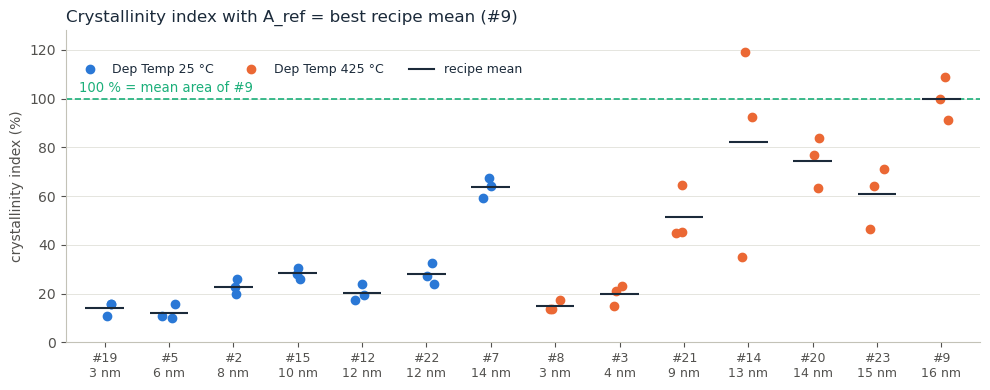

In [8]:
d2 = xrd_best.dropna(subset=['crystallinity_pct'])
order = d2.sort_values(['Dep Temp (°C)', 'thickness_final_nm']).drop_duplicates('run')['run'].tolist(); xp = {r: i for i, r in enumerate(order)}
TC = {25: BLUE, 425: ORANGE}; rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(10, 4))
for _, r in d2.iterrows():
    ax.scatter(xp[r.run] + rng.uniform(-.12, .12), r.crystallinity_pct, s=36, color=TC[r['Dep Temp (°C)']], zorder=3)
for rr, mv in d2.groupby('run').crystallinity_pct.mean().items():
    ax.hlines(mv, xp[rr] - .3, xp[rr] + .3, color=INK, lw=1.5, zorder=4)
ax.axhline(100, color=AQUA, lw=1.2, ls='--', zorder=2)
ax.text(-0.4, 101.5, f'100 % = mean area of #{best_run}', color=AQUA, fontsize=9.5, va='bottom')
ax.set_xticks(range(len(order))); ax.grid(axis='x', visible=False)
ax.set_xticklabels([f"#{r}\n{d2[d2.run == r].thickness_final_nm.iloc[0]:.0f} nm" for r in order], fontsize=9)
ax.set_ylabel('crystallinity index (%)'); ax.set_ylim(0, 128); ax.set_xlim(-0.6, len(order) - 0.4)
ax.set_title(f'Crystallinity index with A_ref = best recipe mean (#{best_run})', loc='left')
ax.legend(handles=[Line2D([], [], marker='o', ls='', color=BLUE, label='Dep Temp 25 °C'), Line2D([], [], marker='o', ls='', color=ORANGE, label='Dep Temp 425 °C'),
                   Line2D([], [], color=INK, lw=1.5, label='recipe mean')], loc='upper left', bbox_to_anchor=(0, 0.93), ncol=3, fontsize=9)
fig.tight_layout(); save('cryst_ref_fig', fig); plt.show()

**Reading 1c.**

* **The best recipe is #9** (425 °C, 9.6 nm deposited = 16 nm final), mean area 305.6 over its three films. #16 has no
  XRD: all three films contact-failed (790 °C anneal) and the failed recipes were not scanned. The next recipe means are
  #14 (251.0) and #20 (227.9).
* **Every index rises by ×1.093** (333.9 / 305.6): #9 = 100 %, #14 = 82 %, #20 = 75 %, and the 25 °C films ≤ 12 nm read 10–33 %.
  Single films can now read above 100 %: 03_14 (119 %) and 03_09 (109 %).
* **The reference depends on the outlier decision**: #14 holds the strongest film (03_14) and the weakest of the
  425 °C thick films (02_14, flagged by Cook's distance in §2). Without 02_14, #14 averages 323.0 and would become the
  reference instead of #9.
* **Nothing else changes**: dividing by a different constant leaves the ranking, the ANOVA F and p, the CV and the outlier
  flags exactly as they are (table above), and the GP/BO in §5–6 would only see a rescaled crystallinity axis. The rest
  of the notebook keeps the top-3 reference, consistent with the XRD notebook and the 08_27 delivery.

## 2. Outlying replicates

Same rule as the earlier ANOVA work in this repository (`analysis/inox/analysis.ipynb`): fit the one-way
model `y ~ C(condition)` for each response and flag films whose **Cook's distance exceeds 4/n**. Cook's distance measures
how much the fitted condition means move when that film is left out:

$$D_i = \frac{e_i^2}{p\,\mathrm{MSE}}\;\frac{h_{ii}}{(1-h_{ii})^2}$$

with residual $e_i$, leverage $h_{ii}$ ($= 1/n_\text{condition}$ here) and $p$ model parameters. Two guards keep the rule
sensible with only three replicates: at most **one** film is removed per condition (the one with the largest $D_i$), and
only if the condition **keeps at least two** replicates, so a condition with two films that disagree is left alone.

In [9]:
def flag_outliers(df, resp):
    sub = df.dropna(subset=[resp]).copy(); sub['y'] = sub[resp]
    m = ols('y ~ C(run)', data=sub).fit()
    sub['cooks_d'] = OLSInfluence(m).cooks_distance[0]
    cut = 4 / len(sub)
    n_per = sub.groupby('run')['y'].transform('size')
    cand = sub[(sub.cooks_d > cut) & (n_per >= 3)].sort_values('cooks_d', ascending=False)
    top = cand.groupby('run').head(1)
    # ignore exact ties (two films equally influential -> no basis to pick one)
    tie = cand.groupby('run').cooks_d.transform(lambda s: (np.isclose(s, s.max())).sum() > 1)
    top = top[~top.index.isin(cand[tie].index)]
    return top[['sample', 'run', resp, 'cooks_d']].assign(response=RESP[resp], cutoff=cut).rename(columns={resp: 'value'})

outliers = pd.concat([flag_outliers(data, r) for r in RESP], ignore_index=True)
clean = data.copy()
for _, o in outliers.iterrows():
    col = [k for k, v in RESP.items() if v == o.response][0]
    clean.loc[clean['sample'] == o['sample'], col] = np.nan
    if col == 'log10_carrier':
        clean.loc[clean['sample'] == o['sample'], 'carrier'] = np.nan
save('outliers_table', outliers)
outliers.round(3)

,sample,run,value,cooks_d,response,cutoff
0,03_08,8,20.267,0.252,log₁₀ carrier (cm⁻³),0.098
1,01_23,23,19.700,0.246,log₁₀ carrier (cm⁻³),0.098
2,02_14,14,32.078,0.687,Crystallinity index (%),0.095


### 2b. Cross-check with the IQR rule

The interquartile-range rule flags a value outside the fences $[Q_1 - 1.5\,\mathrm{IQR},\; Q_3 + 1.5\,\mathrm{IQR}]$, with
$\mathrm{IQR} = Q_3 - Q_1$.

**Inside one recipe the rule cannot flag anything.** For three replicates $a \le b \le c$ the quartiles are
$Q_1 = (a+b)/2$, $Q_3 = (b+c)/2$, so $\mathrm{IQR} = (c-a)/2$ and the lower fence is $(a+b)/2 - 0.75\,(c-a) \le a$, because
$(b-a)/2 \le 0.75\,(c-a)$; symmetrically the upper fence is $\ge c$. The fences always enclose all three films (the cell below
confirms it on the data). The within-replicate check therefore has to borrow its scale from all recipes: each film's
**deviation from its own recipe mean** is the within-replicate quantity, and the fences are set from those deviations pooled
over the 14 recipes. For reference the rule is also applied to the raw values:

* **on the within-recipe deviations** $r_{ij} = y_{ij} - \bar y_i$ (each film minus its own recipe mean), fences from all
  recipes pooled — this asks whether a film disagrees with its own replicates unusually much;
* **on the raw values** of each response, pooled over all films — this mostly measures how different the recipes are.

In [10]:
# literal within-recipe IQR (three films per recipe): count flags per response
within = {}
for r, lab in RESP.items():
    n_flag = 0
    for _, g in data.dropna(subset=[r]).groupby('run'):
        q1, q3 = g[r].quantile([0.25, 0.75]); iqr = q3 - q1
        n_flag += int(((g[r] < q1 - 1.5 * iqr) | (g[r] > q3 + 1.5 * iqr)).sum())
    within[lab] = n_flag
print('IQR computed inside each recipe -> films flagged:', within)

def iqr_flags(df, resp, on='residual'):
    sub = df.dropna(subset=[resp]).copy()
    sub['value'] = sub[resp] - sub.groupby('run')[resp].transform('mean') if on == 'residual' else sub[resp]
    q1, q3 = sub['value'].quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    sub['flag'] = (sub['value'] < lo) | (sub['value'] > hi)
    return sub, (lo, hi)

rows, IQR_RES = [], {}
for r, lab in RESP.items():
    raw, _ = iqr_flags(data, r, on='raw')
    res, fences = iqr_flags(data, r, on='residual'); IQR_RES[r] = (res, fences)
    for _, f in res[res.flag].iterrows():
        removed = ((outliers['sample'] == f['sample']) & (outliers['response'] == lab)).any()
        rows.append(dict(response=lab, sample=f['sample'], recipe=f.run, value=f[r], residual=f['value'],
                         fence=f'[{fences[0]:.3g}, {fences[1]:.3g}]', removed_by_cooks_d=removed))
    print(f'{lab}: raw-value IQR flags {int(raw.flag.sum())} films | residual IQR flags {int(res.flag.sum())} films')
iqr_table = pd.DataFrame(rows)
save('iqr_table', iqr_table)
iqr_table.round(3)

IQR computed inside each recipe -> films flagged: {'Hall mobility (cm²/V·s)': 0, 'log₁₀ carrier (cm⁻³)': 0, 'Crystallinity index (%)': 0}
Hall mobility (cm²/V·s): raw-value IQR flags 0 films | residual IQR flags 2 films
log₁₀ carrier (cm⁻³): raw-value IQR flags 0 films | residual IQR flags 4 films
Crystallinity index (%): raw-value IQR flags 0 films | residual IQR flags 3 films


,response,sample,recipe,value,residual,fence,removed_by_cooks_d
0,Hall mobility (cm²/V·s),01_14,14,9.910,1.815,"[-0.522, 0.478]",False
1,Hall mobility (cm²/V·s),03_14,14,6.280,-1.815,"[-0.522, 0.478]",False
2,log₁₀ carrier (cm⁻³),01_08,8,20.076,-0.094,"[-0.0616, 0.0576]",False
3,log₁₀ carrier (cm⁻³),01_23,23,19.700,0.096,"[-0.0616, 0.0576]",True
4,log₁₀ carrier (cm⁻³),03_08,8,20.267,0.097,"[-0.0616, 0.0576]",True
5,log₁₀ carrier (cm⁻³),03_23,23,19.524,-0.080,"[-0.0616, 0.0576]",False
6,Crystallinity index (%),01_23,23,42.439,-13.083,"[-11.8, 12.2]",False
7,Crystallinity index (%),02_14,14,32.078,-43.093,"[-11.8, 12.2]",True
8,Crystallinity index (%),03_14,14,108.929,33.758,"[-11.8, 12.2]",False


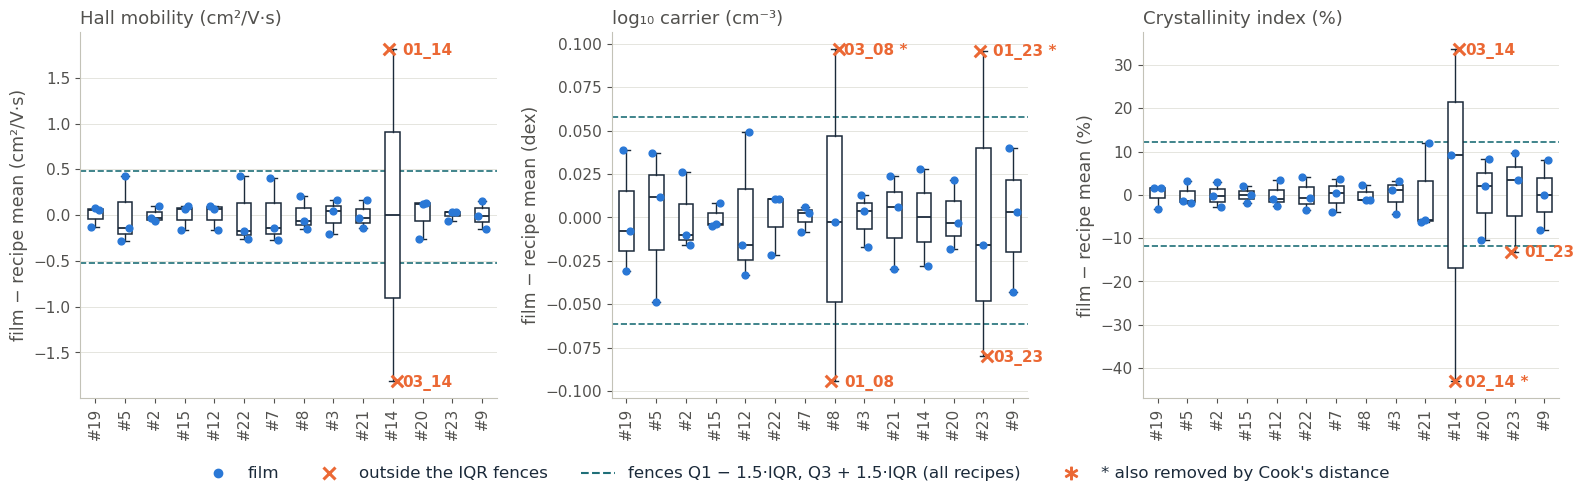

In [11]:
order = data.sort_values(['Dep Temp (°C)', 'thickness_final_nm']).drop_duplicates('run')['run'].tolist()
xpos = {r: i for i, r in enumerate(order)}
units = {'mobility': 'cm²/V·s', 'log10_carrier': 'dex', 'crystallinity_pct': '%'}
BOX = dict(widths=0.5, whis=1.5, showfliers=False, patch_artist=True, boxprops=dict(facecolor='white', edgecolor=INK, lw=1.1),
           medianprops=dict(color=INK, lw=1.3), whiskerprops=dict(color=INK, lw=1.0), capprops=dict(color=INK, lw=1.0))

def recipe_boxes(ax, df, col, flag_mask=None):
    # one narrow box plot per recipe + its films; flagged films drawn as an orange x
    groups = [df.loc[df.run == k, col].to_numpy() for k in order]
    ax.boxplot(groups, positions=range(len(order)), **BOX)
    for i, k in enumerate(order):
        sub = df[df.run == k]
        jit = np.linspace(-0.13, 0.13, len(sub)) if len(sub) > 1 else np.zeros(1)
        f = flag_mask.loc[sub.index].to_numpy() if flag_mask is not None else np.zeros(len(sub), bool)
        ax.scatter(i + jit[~f], sub[col].to_numpy()[~f], s=24, color=BLUE, zorder=3)
        ax.scatter(i + jit[f], sub[col].to_numpy()[f], marker='x', s=70, lw=2.2, color=ORANGE, zorder=4)
    ax.set_xticks(range(len(order))); ax.set_xticklabels([f'#{k}' for k in order], fontsize=11, rotation=90)
    ax.tick_params(axis='y', labelsize=11); ax.grid(axis='x', visible=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (r, lab) in zip(axes, RESP.items()):
    res, (lo, hi) = IQR_RES[r]
    for f in (lo, hi):
        ax.axhline(f, color='#1f6f78', lw=1.2, ls='--', zorder=1)
    recipe_boxes(ax, res, 'value', res['flag'])
    for _, b in res[res.flag].iterrows():
        cooks = ((outliers['sample'] == b['sample']) & (outliers['response'] == lab)).any()
        ax.annotate(b['sample'] + (' *' if cooks else ''), (xpos[b.run], b['value']), xytext=(7, -4), textcoords='offset points', fontsize=11, color=ORANGE, fontweight='bold')
    ax.set_ylabel(f'film − recipe mean ({units[r]})', fontsize=12.5); ax.set_title(lab, loc='left', fontsize=13, color=INK2)
handles = [Line2D([], [], marker='o', ls='', color=BLUE, label='film'), Line2D([], [], marker='x', ls='', color=ORANGE, markersize=9, mew=2.2, label='outside the IQR fences'),
           Line2D([], [], color='#1f6f78', ls='--', label='fences Q1 − 1.5·IQR, Q3 + 1.5·IQR (all recipes)'),
           Line2D([], [], ls='', marker='$*$', color=ORANGE, markersize=9, label="* also removed by Cook's distance")]
fig.legend(handles=handles, loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.09), fontsize=12)
fig.tight_layout(); save('iqr_fig', fig); plt.show()

**Reading 2b.** IQR inside each recipe flags nothing, as the algebra above requires. The raw-value IQR flags nothing either: the spread of the raw values comes from the recipes, not from bad films.
On the residuals the rule flags **9 films in 3 recipes** — both films of #14 for mobility, #14 (02_14, 03_14) and 01_23
for crystallinity, and #8 (01_08, 03_08) and #23 (01_23, 03_23) for carrier. The fences are tight because most replicates
agree within a few per cent, and with three replicates a recipe whose films disagree usually has two films outside: the IQR
rule points at **noisy recipes** rather than at one bad film. All three films removed by Cook's distance in §2 are among
them; the analysis keeps the Cook's-distance removal, which takes at most one film per recipe.

### 2c. What the IQR does with three films per recipe

The cells below compute the IQR **inside each recipe**, show the resulting fences next to the films, and then simulate how
the rule's ability to catch an outlier depends on the number of replicates.

In [12]:
# per-recipe quartiles and fences (numpy/pandas default: linear interpolation)
rows = []
for r, lab in RESP.items():
    for run_, g in data.dropna(subset=[r]).groupby('run'):
        v = np.sort(g[r].to_numpy())
        q1, q3 = np.quantile(v, [0.25, 0.75]); iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        rows.append(dict(response=lab, recipe=run_, n=len(v), films=', '.join(f'{x:.3g}' for x in v), Q1=q1, Q3=q3, IQR=iqr,
                         lower_fence=lo, upper_fence=hi, margin_below=v.min() - lo, margin_above=hi - v.max(),
                         flagged=int(((v < lo) | (v > hi)).sum())))
within_tbl = pd.DataFrame(rows)
print('Films flagged by the per-recipe IQR, all responses:', int(within_tbl.flagged.sum()))
print('Smallest distance between a film and its fence (always > 0):', float(within_tbl[['margin_below', 'margin_above']].min().min().round(4)))
# the three most dispersed recipes per response, as examples
ex = within_tbl.assign(rel=within_tbl.IQR / within_tbl.Q3.abs()).sort_values('rel', ascending=False).groupby('response').head(2)
ex[['response', 'recipe', 'n', 'films', 'Q1', 'Q3', 'IQR', 'lower_fence', 'upper_fence', 'flagged']].round(3)

Films flagged by the per-recipe IQR, all responses: 0
Smallest distance between a film and its fence (always > 0): 0.0041


,response,recipe,n,films,Q1,Q3,IQR,lower_fence,upper_fence,flagged
35,Crystallinity index (%),14,3,"32.1, 84.5, 109",58.293,96.718,38.426,0.654,154.357,0
30,Crystallinity index (%),5,3,"9.2, 9.81, 14.3",9.504,12.076,2.572,5.647,15.934,0
7,Hall mobility (cm²/V·s),14,2,"6.28, 9.91",7.188,9.002,1.815,4.465,11.725,0
2,Hall mobility (cm²/V·s),5,3,"1.91, 2.06, 2.62",1.985,2.340,0.355,1.452,2.872,0
18,log₁₀ carrier (cm⁻³),8,3,"20.1, 20.2, 20.3",20.121,20.217,0.096,19.978,20.361,0
27,log₁₀ carrier (cm⁻³),23,3,"19.5, 19.6, 19.7",19.556,19.644,0.088,19.424,19.776,0


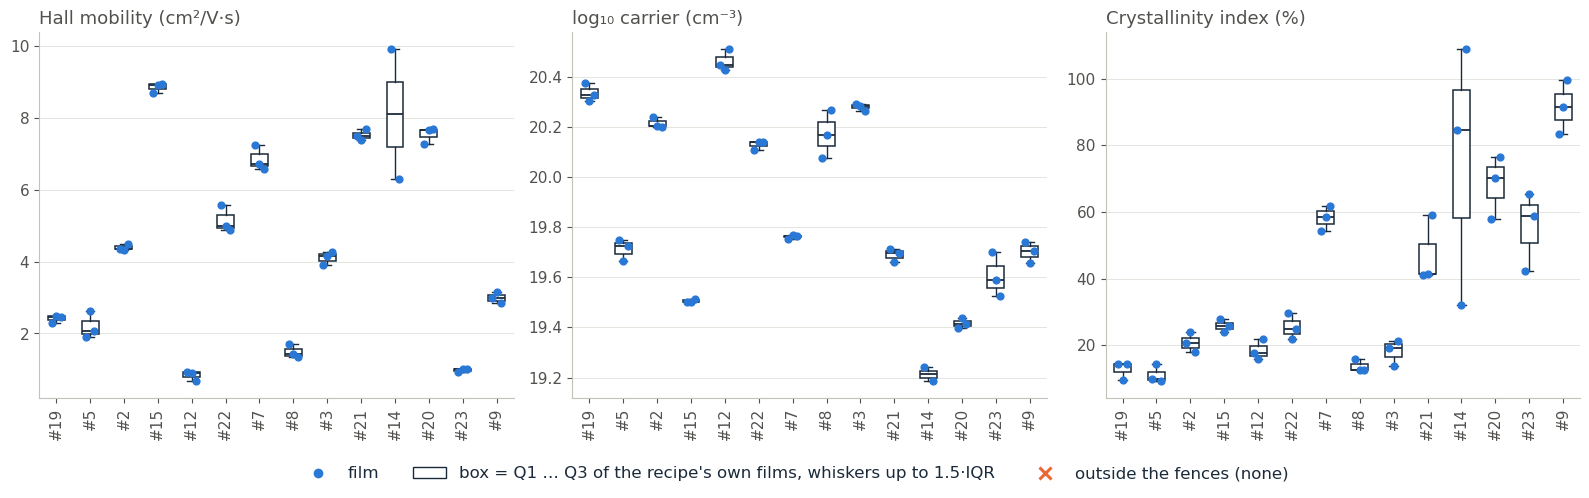

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (r, lab) in zip(axes, RESP.items()):
    sub = data.dropna(subset=[r]).copy()
    # outside the recipe's OWN fences (Q1, Q3 from that recipe's films only)
    q = sub.groupby('run')[r].quantile([0.25, 0.75]).unstack()
    lo_ = sub.run.map(q[0.25] - 1.5 * (q[0.75] - q[0.25])); hi_ = sub.run.map(q[0.75] + 1.5 * (q[0.75] - q[0.25]))
    recipe_boxes(ax, sub, r, (sub[r] < lo_) | (sub[r] > hi_))
    ax.set_title(lab, loc='left', fontsize=13, color=INK2)
handles = [Line2D([], [], marker='o', ls='', color=BLUE, label='film'),
           plt.Rectangle((0, 0), 1, 1, facecolor='white', edgecolor=INK, label="box = Q1 … Q3 of the recipe's own films, whiskers up to 1.5·IQR"),
           Line2D([], [], marker='x', ls='', color=ORANGE, markersize=9, mew=2.2, label='outside the fences (none)')]
fig.legend(handles=handles, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.09), fontsize=12)
fig.tight_layout(); save('iqr_within_fig', fig); plt.show()

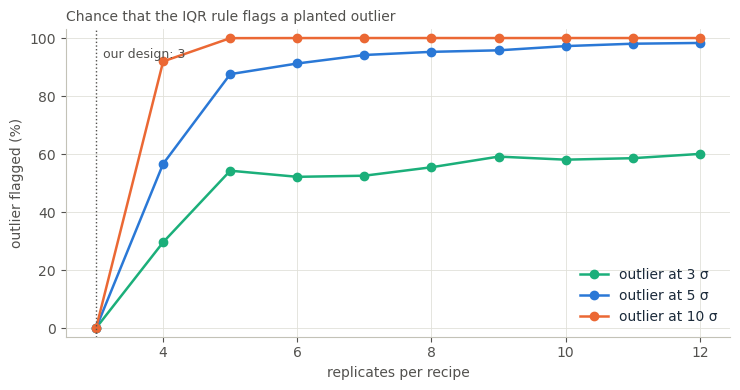

,outlier at 3 σ,outlier at 5 σ,outlier at 10 σ
replicates per recipe,,,
3,0.0,0.0,0.0
4,29.6,56.6,91.9
5,54.2,87.6,100.0
6,52.1,91.2,100.0
7,52.5,94.2,100.0
8,55.4,95.2,100.0
9,59.1,95.8,100.0
10,58.1,97.2,100.0
11,58.6,98.0,100.0


In [14]:
# simulation: n - 1 normal replicates + 1 planted outlier at +delta standard deviations; how often does the IQR rule flag it?
rng = np.random.default_rng(GLOBAL_SEED)
N_SIM, NS, DELTAS = 20000, range(3, 13), [3, 5, 10]
sim = pd.DataFrame(index=list(NS), columns=[f'outlier at {dl} σ' for dl in DELTAS], dtype=float)
for n in NS:
    for dl in DELTAS:
        x = rng.standard_normal((N_SIM, n)); x[:, -1] = dl                                   # last value = planted outlier
        q1, q3 = np.quantile(x, [0.25, 0.75], axis=1); iqr = q3 - q1
        sim.loc[n, f'outlier at {dl} σ'] = np.mean(x[:, -1] > q3 + 1.5 * iqr)
sim.index.name = 'replicates per recipe'
fig, ax = plt.subplots(figsize=(7.5, 4))
for (col, c) in zip(sim.columns, [AQUA, BLUE, ORANGE]):
    ax.plot(sim.index, 100 * sim[col], marker='o', color=c, lw=1.8, label=col)
ax.axvline(3, color=INK2, lw=1, ls=':'); ax.text(3.1, 93, 'our design: 3', fontsize=9, color=INK2)
ax.set_xlabel('replicates per recipe'); ax.set_ylabel('outlier flagged (%)'); ax.set_ylim(-3, 103); ax.legend(loc='lower right')
ax.set_title('Chance that the IQR rule flags a planted outlier', loc='left', fontsize=10, color=INK2)
fig.tight_layout(); save('iqr_sim_fig', fig); plt.show()
(100 * sim).round(1)

**Reading 2c.**

* **On the data**: 0 of 124 film-response values are flagged. The fences always reach past the most extreme film; the
  narrowest margin is 0.004. The clearest case is #14 crystallinity, films 32, 85 and 109 %: Q1 = 58, Q3 = 97, IQR = 38, so
  the fences run from 1 to 154 % and enclose the 32 % film that disagrees with the other two.
* **Why**: with three films the quartiles are built from those same three films, so one stray film widens the IQR by
  exactly the amount it strays. The fence moves with it. Algebraically the fence is always beyond the extreme film (§2b).
* **Simulation**: with 3 replicates the rule never flags a planted outlier, even one 10 σ away. With 4 replicates it
  catches a 5 σ outlier 57 % of the time; from 5 replicates onward it catches it ~88–98 % of the time. A 3 σ outlier is
  caught at most ~55–60 % of the time at any size.
* **Practical meaning**: a per-recipe outlier test needs at least five replicates per recipe. With three, outliers have to
  be judged against the noise of all recipes together (§2b), or with the model-based Cook's distance (§2).

## 3. Coefficient of variation per condition

$\mathrm{CV} = 100\,s/\bar y$ over the replicates of a condition (carrier concentration on the raw scale, as in the
earlier notebook). Lower CV = more repeatable condition. The table gives mean and CV for every response, first with all
replicates, then with the outliers of §2 removed.

In [15]:
def cv_table(df):
    out = pd.DataFrame(index=sorted(df.run.unique())); out.index.name = 'condition'
    for col, lab in [('mobility', 'mobility'), ('carrier', 'carrier'), ('crystallinity_pct', 'crystallinity')]:
        g = df.groupby('run')[col]
        out[f'{lab} n'] = g.count()
        out[f'{lab} mean'] = g.mean()
        out[f'{lab} CV %'] = 100 * g.std(ddof=1) / g.mean()
    return out

cv_all, cv_clean = cv_table(data), cv_table(clean)
fmt = {'mobility mean': '{:.2f}', 'mobility CV %': '{:.1f}', 'carrier mean': '{:.2e}', 'carrier CV %': '{:.1f}',
       'crystallinity mean': '{:.1f}', 'crystallinity CV %': '{:.1f}', 'mobility n': '{:.0f}', 'carrier n': '{:.0f}', 'crystallinity n': '{:.0f}'}
print('All replicates')
display(cv_all.style.format(fmt, na_rep='—'))
print('Outliers removed (§2)')
display(cv_clean.style.format(fmt, na_rep='—'))

All replicates


,mobility n,mobility mean,mobility CV %,carrier n,carrier mean,carrier CV %,crystallinity n,crystallinity mean,crystallinity CV %
condition,,,,,,,,,
2,3,4.39,1.9,3,1.64e+20,5.3,3,20.9,14.3
3,3,4.10,4.6,3,1.90e+20,3.5,3,18.1,21.7
5,3,2.20,17.0,3,5.17e+19,10.0,3,11.1,25.3
7,3,6.85,5.2,3,5.77e+19,1.7,3,58.2,6.5
8,3,1.49,12.6,3,1.50e+20,22.0,3,13.7,13.9
9,3,2.99,5.0,3,5.04e+19,9.5,3,91.5,8.8
12,3,0.84,17.4,3,2.90e+20,10.2,3,18.5,16.2
14,2,8.10,31.7,2,1.64e+19,9.1,3,75.2,52.2
15,3,8.84,1.6,3,3.20e+19,1.7,3,25.9,7.6


Outliers removed (§2)


,mobility n,mobility mean,mobility CV %,carrier n,carrier mean,carrier CV %,crystallinity n,crystallinity mean,crystallinity CV %
condition,,,,,,,,,
2,3,4.39,1.9,3,1.64e+20,5.3,3,20.9,14.3
3,3,4.10,4.6,3,1.90e+20,3.5,3,18.1,21.7
5,3,2.20,17.0,3,5.17e+19,10.0,3,11.1,25.3
7,3,6.85,5.2,3,5.77e+19,1.7,3,58.2,6.5
8,3,1.49,12.6,2,1.33e+20,14.9,3,13.7,13.9
9,3,2.99,5.0,3,5.04e+19,9.5,3,91.5,8.8
12,3,0.84,17.4,3,2.90e+20,10.2,3,18.5,16.2
14,2,8.10,31.7,2,1.64e+19,9.1,2,96.7,17.9
15,3,8.84,1.6,3,3.20e+19,1.7,3,25.9,7.6


In [16]:
summary = pd.DataFrame({
    'median CV %, all replicates':   [cv_all[f'{k} CV %'].median() for k in ['mobility', 'carrier', 'crystallinity']],
    'median CV %, outliers removed': [cv_clean[f'{k} CV %'].median() for k in ['mobility', 'carrier', 'crystallinity']],
    'max CV %, all replicates':      [cv_all[f'{k} CV %'].max() for k in ['mobility', 'carrier', 'crystallinity']],
    'max CV %, outliers removed':    [cv_clean[f'{k} CV %'].max() for k in ['mobility', 'carrier', 'crystallinity']],
}, index=['Hall mobility', 'carrier concentration', 'crystallinity index']).round(1)
cv_export = cv_all.add_suffix(' (all)').join(cv_clean.add_suffix(' (no outliers)')).reset_index()
save('cv_table', cv_export)
summary

,"median CV %, all replicates","median CV %, outliers removed","max CV %, all replicates","max CV %, outliers removed"
Hall mobility,5.1,5.1,31.7,31.7
carrier concentration,7.2,7.2,22.0,14.9
crystallinity index,15.8,15.8,52.2,25.3


**Reading §3.** Three films are flagged and removed: **02_14** for crystallinity (32 % against 85 and 109 % for its
replicates) and **03_08** and **01_23** for carrier concentration. Mobility has no removable outlier: condition #14 has
only two valid films (9.9 and 6.3 cm²/V·s), which tie on Cook's distance, so neither can be singled out.

| response | median CV | max CV, all | max CV, outliers removed |
|---|---|---|---|
| Hall mobility | 5.1 % | 31.7 % (#14) | 31.7 % (#14, only 2 films) |
| carrier concentration | 7.2 % | 22.0 % (#8) | 14.9 % |
| crystallinity index | 15.8 % | 52.2 % (#14) | 25.3 % (#5) |

* **Hall data are repeatable**: median CV 5–7 %, so the recipe, not the measurement, sets mobility and carrier.
* **Crystallinity is noisier** (median ≈ 16 %), largely because films without a resolved peak sit at a 10–25 % floor where
  small absolute differences become large relative ones (#5, #3, #19, all amorphous).
* Removing outliers changes the medians not at all; it only removes the extremes.

## 4. ANOVA — F and p

One-way model per response, $y_{ij} = \mu + \tau_i + \varepsilon_{ij}$ (group $i$, replicate $j$). The total sum of squares
splits into a between-group and a within-group part, $SS_T = SS_B + SS_W$, and the test statistic is

$$F = \frac{SS_B/(k-1)}{SS_W/(N-k)}$$

with $k$ groups and $N$ films. Under "no group effect" $F$ follows an $F(k-1,\,N-k)$ distribution; the p-value is the
probability of an $F$ at least this large by chance.

* **Between conditions** — the groups are the 14 recipes: does the recipe explain the response beyond replicate noise?
* **Per factor** — the groups are the two levels of a factor (two-level factors) or the two halves split at its median
  (continuous factors), the method of the earlier Experiment 02 notebook. One test per factor and response.

*Why the slides showed η² before:* $\eta^2 = SS_B/SS_T$ is an effect size, comparable across responses and sample sizes,
whereas F and p also grow with the number of films. Both come from the same sums of squares; this notebook reports F and p.

In [17]:
def between_condition(df, resp):
    sub = df.dropna(subset=[resp]).copy(); sub['y'] = sub[resp]
    t = sm.stats.anova_lm(ols('y ~ C(run)', data=sub).fit(), typ=2)
    return dict(N=len(sub), k=sub.run.nunique(), df_between=int(t.loc['C(run)', 'df']), df_within=int(t.loc['Residual', 'df']),
                F=t.loc['C(run)', 'F'], p=t.loc['C(run)', 'PR(>F)'])

rows = []
for tag, df_ in [('all replicates', data), ('outliers removed', clean)]:
    for r, lab in RESP.items():
        rows.append(dict(data=tag, response=lab, **between_condition(df_, r)))
anova_between = pd.DataFrame(rows)
save('anova_between', anova_between)
anova_between.style.format({'F': '{:.1f}', 'p': '{:.1e}'})

,data,response,N,k,df_between,df_within,F,p
0,all replicates,Hall mobility (cm²/V·s),41,14,13,27,78.1,6.1e-18
1,all replicates,log₁₀ carrier (cm⁻³),41,14,13,27,206.9,1.6e-23
2,all replicates,Crystallinity index (%),42,14,13,28,14.8,3.1e-09
3,outliers removed,Hall mobility (cm²/V·s),41,14,13,27,78.1,6.1e-18
4,outliers removed,log₁₀ carrier (cm⁻³),39,14,13,25,384.8,2.0e-25
5,outliers removed,Crystallinity index (%),41,14,13,27,49.9,2.0e-15


In [18]:
def per_factor(df, resp):
    sub = df.dropna(subset=[resp]); out = []
    for f in FACTORS:
        x = sub[f].values; u = np.unique(x)
        if len(u) == 2:
            groups, split = [sub[resp][x == v].values for v in u], 'two levels'
        else:
            med = np.median(x); groups, split = [sub[resp][x <= med].values, sub[resp][x > med].values], f'median {med:g}'
        F, p = stats.f_oneway(*groups)
        out.append(dict(factor=f, split=split, F=F, p=p))
    return pd.DataFrame(out).set_index('factor')

pf_clean = {lab: per_factor(clean, r) for r, lab in RESP.items()}
pf_all = {lab: per_factor(data, r) for r, lab in RESP.items()}
wide = pd.concat({lab: t[['F', 'p']] for lab, t in pf_clean.items()}, axis=1)
wide.insert(0, 'split', pf_clean[RESP['mobility']]['split'])
order = wide[[(l, 'p') for l in RESP.values()]].min(axis=1).sort_values().index
wide = wide.loc[order]
save('anova_per_factor', wide.reset_index())

def _star(v):
    return 'font-weight: bold; color: #b5471b' if v < 0.05 else ''
fmt = {(l, 'F'): '{:.1f}' for l in RESP.values()} | {(l, 'p'): '{:.4f}' for l in RESP.values()}
print('Per-factor one-way ANOVA, outliers removed (bold: p < 0.05)')
display(wide.style.format(fmt).map(_star, subset=[(l, 'p') for l in RESP.values()]))
flips = [(lab, f) for lab in RESP.values() for f in FACTORS if (pf_all[lab].loc[f, 'p'] < 0.05) != (pf_clean[lab].loc[f, 'p'] < 0.05)]
print('Significance changes when outliers are removed:', flips or 'none')

Per-factor one-way ANOVA, outliers removed (bold: p < 0.05)


Significance changes when outliers are removed: [('Crystallinity index (%)', 'Vac Ann Temp (°C)'), ('Crystallinity index (%)', 'Vac Ann Time (min)')]


**Reading §4.**

*Between conditions* (outliers removed): mobility F = 78 (p ≈ 6·10⁻¹⁸), log carrier F = 385 (p ≈ 2·10⁻²⁵), crystallinity
F = 50 (p ≈ 2·10⁻¹⁵). The recipe matters far beyond replicate noise for all three. Removing the outliers raises F for carrier
(207 → 385) and crystallinity (15 → 50) because the within-condition noise $SS_W$ shrinks.

*Per factor*, significant at p < 0.05:

| response | factors (F, largest first) |
|---|---|
| Hall mobility | oxidation pressure (73.4), deposition power (7.7), anneal time (6.2), oxidation temperature (4.2) |
| log₁₀ carrier | deposition pressure (14.5), oxidation temperature (8.6), deposition temperature (6.9), oxidation pressure (5.7), O₂ flow (4.7) |
| crystallinity | deposited thickness (27.7), deposition pressure (19.9), deposition temperature (14.6), anneal temperature (4.4) |

Removing the outliers moves two crystallinity results across the 0.05 line: anneal temperature becomes significant and
anneal time stops being significant. Both are near the threshold and should not be over-read.

Caveats: the per-factor test splits continuous factors at the median and treats the 41 films as independent although
replicates of one recipe are not; with 14 recipes several factors are partly confounded (e.g. deposition pressure with
thickness). This is screening; the GP of §5 looks at all factors jointly.

## 5. A three-output Gaussian process on the current data

One `SingleTaskGP` from `utils/mobo.py` on the **14 condition means** (outliers of §2 removed), inputs scaled to the unit
cube of the sapphire design, outputs in maximisation form: **mobility**, **−log₁₀ carrier**, **−crystallinity**. Each
training point is a mean of 2–3 replicates, so its noise is fixed to the variance of that mean, $\mathrm{SEM}^2 = s^2/n$,
the campaign convention (`train_Yvar`).

Leave-one-out: each condition in turn is removed, the GP refitted on the other 13 and asked to predict it. $R^2$ and RMSE
measure accuracy; mean $|z| = |y - \hat y|/\hat\sigma$ checks calibration (≈ 0.8 for well-calibrated Gaussian errors,
larger = over-confident).

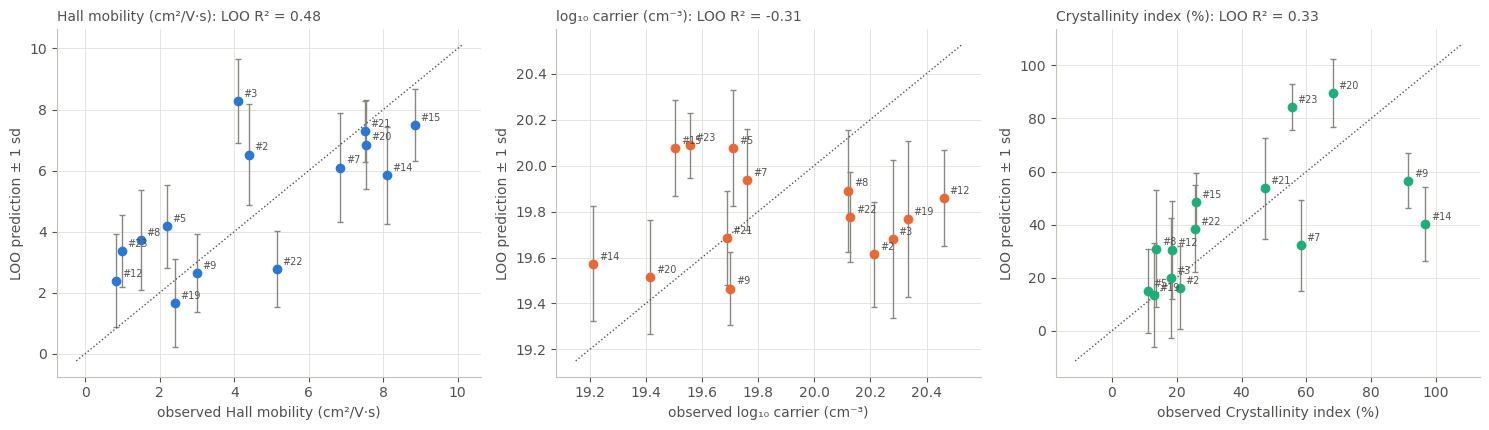

,response,LOO R²,LOO RMSE,mean |z|
0,Hall mobility (cm²/V·s),0.482,1.952,1.186
1,log₁₀ carrier (cm⁻³),-0.308,0.427,1.693
2,Crystallinity index (%),0.330,23.235,1.375


In [19]:
CONT = {'Dep Power (W)': (0, 40), 'O2 Flow (sccm)': (0.3, 20), 'Dep Press (mTorr)': (2, 10), 'Ox Temp (°C)': (200, 800),
        'Ox Time (min)': (0, 120), 'Vac Ann Temp (°C)': (25, 800), 'Vac Ann Time (min)': (0, 120), 'Dep Thickness (nm)': (1, 10)}
CAT = {'Dep Temp (°C)': [25.0, 425.0], 'Ox Press (atm)': [0.02, 1.0]}
OBJ = ['mobility', 'log10_carrier', 'crystallinity_pct']
SIGN = np.array([1.0, -1.0, -1.0])                      # botorch maximises: mobility, -log10 carrier, -crystallinity

cond = clean.groupby('run').agg(**{f: (f, 'first') for f in FACTORS}, **{o: (o, 'mean') for o in OBJ}).dropna().reset_index()
Xu = mobo.encode_unit(cond, FACTORS, CONT, CAT)
Y = cond[OBJ].to_numpy() * SIGN
Yvar = np.column_stack([mobo.variance_of_mean_by_group(clean, 'run', o).reindex(cond.run).to_numpy() for o in OBJ])
model = mobo.fit_gp(Xu, Y, Yvar=Yvar)

P = np.zeros_like(Y); S = np.zeros_like(Y)
for i in range(len(Y)):
    keep = np.arange(len(Y)) != i
    m_i = mobo.fit_gp(Xu[keep], Y[keep], Yvar=Yvar[keep])
    post = m_i.posterior(torch.tensor(Xu[i:i + 1], dtype=torch.double))
    P[i], S[i] = post.mean.detach().numpy()[0], post.variance.sqrt().detach().numpy()[0]
from sklearn.metrics import r2_score
loo = pd.DataFrame({'response': list(RESP.values()),
                    'LOO R²': [r2_score(Y[:, j], P[:, j]) for j in range(3)],
                    'LOO RMSE': [np.sqrt(np.mean((Y[:, j] - P[:, j]) ** 2)) for j in range(3)],
                    'mean |z|': [np.mean(np.abs(Y[:, j] - P[:, j]) / S[:, j]) for j in range(3)]}).round(3)
save('gp_loo_table', loo)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for j, (ax, lab) in enumerate(zip(axes, RESP.values())):
    yt, yp, ys = Y[:, j] * SIGN[j], P[:, j] * SIGN[j], S[:, j]
    ax.errorbar(yt, yp, yerr=ys, fmt='o', ms=6, color=[BLUE, ORANGE, AQUA][j], ecolor=MUTED, elinewidth=1, capsize=2.5)
    lo, hi = min(yt.min(), (yp - ys).min()), max(yt.max(), (yp + ys).max()); pad = 0.05 * (hi - lo)
    ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], color=INK2, lw=1, ls=':')
    for k_, r_ in enumerate(cond.run):
        ax.annotate(f'#{r_}', (yt[k_], yp[k_]), xytext=(4, 3), textcoords='offset points', fontsize=7, color=INK2)
    ax.set_xlabel(f'observed {lab}'); ax.set_ylabel('LOO prediction ± 1 sd')
    ax.set_title(f"{lab}: LOO R² = {loo.loc[j, 'LOO R²']:.2f}", loc='left', fontsize=10, color=INK2)
fig.tight_layout(); save('gp_loo_fig', fig); plt.show()
loo

**Reading §5.** With 14 recipes in 10 dimensions the GP is still data-starved:

| response | LOO R² | LOO RMSE | mean \|z\| |
|---|---|---|---|
| Hall mobility | 0.48 | 1.95 cm²/V·s | 1.19 |
| log₁₀ carrier | −0.31 | 0.43 dex | 1.69 |
| crystallinity index | 0.33 | 23 % | 1.38 |

* **Mobility** is partly predictable: it ranks most held-out recipes correctly; #3 is the clear miss.
* **Carrier concentration is not yet predictable** from the other 13 recipes (negative R²: worse than predicting the
  mean). Its between-condition F is the largest of the three, so the recipe does determine it; the model simply has too
  few recipes to learn how.
* **Crystallinity** follows thickness, which the GP picks up, but it misses the thick 425 °C films #9 and #14.
* The uncertainties are somewhat too narrow (mean |z| 1.2–1.7 instead of ≈ 0.8), so the error bars in §6 should be read
  as optimistic.

This is the expected state after one 23-recipe batch with 9 failures, and the reason the next batch matters more than any
model choice.

## 6. What the current data state says about new samples

Two views, both from the GP of §5 — i.e. **trained on Al₂O₃ / sapphire only**:

* **Planned Experiment 04 recipes.** The GP's predicted mean ± sd at the 46 recipes of the sliced-LHS run sheet. These
  points were chosen for coverage, not performance; the prediction shows where the model expects them to land and how
  uncertain it is.
* **What BO would propose next.** A batch of `Q_BO` recipes maximising qLogNEHVI (expected hypervolume improvement over the
  observed Pareto front of the three objectives), searched inside the Experiment 04 box: anneal ≤ 300 °C, oxidation ≤ 700 °C,
  power ≥ 2 W, both two-level factors enumerated.

Caveat for both: the base substrate changes to Si, which ND says runs hotter under the IR lamp, so these are what the
sapphire data imply, not predictions for the Si stacks. That transfer is exactly what the first Si batch will test.

In [20]:
Q_BO = 5
j = FACTORS.index
lo, hi = np.zeros(len(FACTORS)), np.ones(len(FACTORS))
hi[j('Vac Ann Temp (°C)')] = (300 - 25) / (800 - 25)
hi[j('Ox Temp (°C)')] = (700 - 200) / (800 - 200)
lo[j('Dep Power (W)')] = 2 / 40
bounds = torch.tensor(np.vstack([lo, hi]), dtype=torch.double)
cat_idx = [j('Dep Temp (°C)'), j('Ox Press (atm)')]
ff_list = [{cat_idx[0]: a, cat_idx[1]: b} for a in (0.0, 1.0) for b in (0.0, 1.0)]

pareto_mask, hv, ref_point = mobo.pareto_front(Y)
cand, joint, indiv, _ = mobo.propose_candidates(model, ref_point, X_baseline=torch.tensor(Xu), bounds=bounds, q=Q_BO,
                                                 fixed_features_list=ff_list, num_restarts=10, raw_samples=256,
                                                 mc_samples=128, seed=GLOBAL_SEED)
order = np.argsort(-indiv); cand = cand[order]
post = model.posterior(cand); pm = post.mean.detach().numpy() * SIGN; ps = post.variance.sqrt().detach().numpy()
proposals = mobo.decode_unit(cand.numpy(), FACTORS, CONT, CAT, {f: 1 for f in FACTORS})
proposals.insert(0, 'candidate', [f'B{i + 1}' for i in range(Q_BO)])
for k_, o in enumerate(OBJ):
    proposals[f'pred {o}'] = pm[:, k_]; proposals[f'sd {o}'] = ps[:, k_]
proposals['carrier (cm⁻³)'] = 10 ** proposals['pred log10_carrier']
save('bo_proposals', proposals)
print(f"Observed Pareto front: conditions {cond.run[pareto_mask.numpy()].tolist()} | joint qLogNEHVI of the batch {joint:.3f}")
proposals.round(2)

Observed Pareto front: conditions [2, 3, 5, 14, 15, 19, 20, 22] | joint qLogNEHVI of the batch -3.151


,candidate,Dep Power (W),O2 Flow (sccm),Dep Press (mTorr),Dep Temp (°C),Ox Temp (°C),Ox Press (atm),Ox Time (min),Vac Ann Temp (°C),Vac Ann Time (min),Dep Thickness (nm),pred mobility,sd mobility,pred log10_carrier,sd log10_carrier,pred crystallinity_pct,sd crystallinity_pct,carrier (cm⁻³)
0,B1,40.0,0.3,6.4,25.0,700.0,0.02,79.0,300.0,97.8,7.0,9.13,0.91,19.32,0.17,38.67,11.61,2.089219e+19
1,B2,40.0,20.0,2.0,25.0,700.0,0.02,108.0,300.0,6.9,4.5,8.43,1.46,19.59,0.21,17.25,17.89,3.889454e+19
2,B3,30.9,8.5,2.7,25.0,700.0,0.02,87.4,300.0,104.9,4.3,9.17,0.89,19.51,0.19,13.75,15.51,3.243787e+19
3,B4,2.0,20.0,2.0,25.0,700.0,0.02,76.2,300.0,104.8,7.0,8.87,1.26,19.44,0.22,33.19,16.56,2.768249e+19
4,B5,2.0,0.3,2.0,25.0,700.0,0.02,62.9,25.0,64.7,4.1,8.47,1.23,19.60,0.20,11.59,16.31,3.970338e+19


In [21]:
# GP predictions at the 46 planned Experiment 04 recipes
x04 = pd.ExcelFile(DESIGN04)
planned = pd.concat([pd.read_excel(x04, 'AlSi_unique').assign(stack='Al₂O₃ / Si'), pd.read_excel(x04, 'TiSi_unique').assign(stack='TiO₂ / Si')], ignore_index=True)
pp = model.posterior(torch.tensor(mobo.encode_unit(planned, FACTORS, CONT, CAT), dtype=torch.double))
pl_m = pp.mean.detach().numpy() * SIGN; pl_s = pp.variance.sqrt().detach().numpy()
for k_, o in enumerate(OBJ):
    planned[f'pred {o}'] = pl_m[:, k_]; planned[f'sd {o}'] = pl_s[:, k_]
obs_sd = np.sqrt(Yvar)
print('Median predicted sd at the planned recipes vs at the training points:')
pd.DataFrame({'planned recipes': [np.median(pl_s[:, k_]) for k_ in range(3)],
              'training points (LOO)': [np.median(S[:, k_]) for k_ in range(3)]}, index=list(RESP.values())).round(2)

Median predicted sd at the planned recipes vs at the training points:


,planned recipes,training points (LOO)
Hall mobility (cm²/V·s),1.12,1.40
log₁₀ carrier (cm⁻³),0.17,0.22
Crystallinity index (%),15.28,16.15


utopia (target): {'mobility': 15.0, 'log10_carrier': 19.0, 'crystallinity_pct': 0.0} | best observed: {'mobility': np.float64(8.84), 'log10_carrier': np.float64(19.21), 'crystallinity_pct': np.float64(11.12)}
Hall mobility (cm²/V·s) vs log₁₀ carrier (cm⁻³): frontier recipes ['#14', '#15']
Hall mobility (cm²/V·s) vs crystallinity index (%): frontier recipes ['#5', '#19', '#3', '#2', '#22', '#15']
log₁₀ carrier (cm⁻³) vs crystallinity index (%): frontier recipes ['#5', '#15', '#20', '#14']


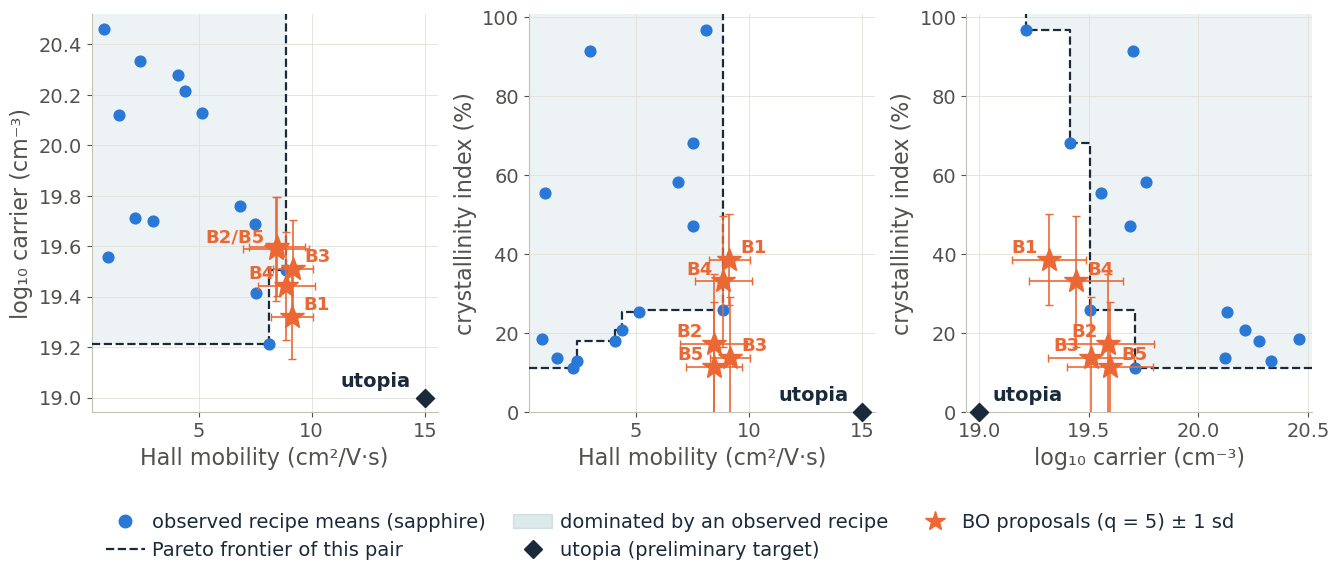

In [22]:
def pareto_2d(f1, f2):
    # indices of the 2-D non-dominated points (both in maximisation form), sorted by f1 ascending (so f2 descending)
    idx = [i for i in range(len(f1)) if not any((f1[j] >= f1[i]) and (f2[j] >= f2[i]) and ((f1[j] > f1[i]) or (f2[j] > f2[i])) for j in range(len(f1)))]
    return sorted(idx, key=lambda i: f1[i])

def frontier_path(xv, yv, sx, sy, xlim, ylim):
    # Staircase boundary of the region dominated by the 2-D Pareto set, extended to the plot edges.
    # sx, sy = +1 (higher is better) or -1 (lower is better). In maximisation space the boundary runs
    # (-inf, f2_0) -> (f1_0, f2_0) -> (f1_0, f2_1) -> (f1_1, f2_1) -> ... -> (f1_k, f2_k) -> (f1_k, -inf).
    idx = pareto_2d(sx * xv, sy * yv)
    px, py = xv[idx], yv[idx]
    x_worst = xlim[0] if sx > 0 else xlim[1]
    y_worst = ylim[0] if sy > 0 else ylim[1]
    X, Y = [x_worst], [py[0]]
    for i in range(len(px)):
        X.append(px[i]); Y.append(py[i])
        if i + 1 < len(px):
            X.append(px[i]); Y.append(py[i + 1])
    X.append(px[-1]); Y.append(y_worst)
    return np.array(X), np.array(Y), (x_worst, y_worst), idx

def _lims(arrays, pad=0.04):
    v = np.concatenate([np.ravel(np.asarray(a, float)) for a in arrays]); lo, hi = np.nanmin(v), np.nanmax(v); p = (hi - lo) * pad
    return lo - p, hi + p

obs = cond.assign(pareto=pareto_mask.numpy())
SGN = {'mobility': 1.0, 'log10_carrier': -1.0, 'crystallinity_pct': -1.0}
LAB = {'mobility': 'Hall mobility (cm²/V·s)', 'log10_carrier': 'log₁₀ carrier (cm⁻³)', 'crystallinity_pct': 'crystallinity index (%)'}
# Utopia point = preliminary TARGET set by the project (decision 2026-10-01), not a measured value:
# 15 cm²/V·s (best mobility seen anywhere in the campaign: 15.3 for the 5 nm HfO2 film), 1e19 cm⁻³, fully amorphous (0 %).
UTOPIA = {'mobility': 15.0, 'log10_carrier': 19.0, 'crystallinity_pct': 0.0}
utopia = UTOPIA
best_obs = {'mobility': obs.mobility.max(), 'log10_carrier': obs.log10_carrier.min(), 'crystallinity_pct': obs.crystallinity_pct.min()}
print('utopia (target):', UTOPIA, '| best observed:', {k: round(v, 2) for k, v in best_obs.items()})
FS_LAB, FS_TICK, FS_ANN = 16, 14, 13
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.9))
for ax, (xk, yk) in zip(axes, [('mobility', 'log10_carrier'), ('mobility', 'crystallinity_pct'), ('log10_carrier', 'crystallinity_pct')]):
    xlim = _lims([obs[xk], proposals[f'pred {xk}'] - proposals[f'sd {xk}'], proposals[f'pred {xk}'] + proposals[f'sd {xk}'], [utopia[xk]]])
    ylim = _lims([obs[yk], proposals[f'pred {yk}'] - proposals[f'sd {yk}'], proposals[f'pred {yk}'] + proposals[f'sd {yk}'], [utopia[yk]]])
    FLOOR = {'mobility': 0.0, 'crystallinity_pct': 0.0}                     # physical floors: no negative mobility / crystallinity
    xlim = (max(xlim[0], FLOOR.get(xk, -np.inf)), xlim[1]); ylim = (max(ylim[0], FLOOR.get(yk, -np.inf)), ylim[1])
    X, Y, corner, fr = frontier_path(obs[xk].to_numpy(), obs[yk].to_numpy(), SGN[xk], SGN[yk], xlim, ylim)
    ax.fill(np.r_[X, corner[0]], np.r_[Y, corner[1]], color='#1f6f78', alpha=0.08, lw=0, zorder=1)     # dominated region
    ax.plot(X, Y, color=INK, lw=1.6, ls='--', zorder=3)
    print(f"{LAB[xk]} vs {LAB[yk]}: frontier recipes {[f'#{r_}' for r_ in obs.run.to_numpy()[fr]]}")
    ax.scatter(obs[xk], obs[yk], s=60, color=BLUE, zorder=4)
    ax.errorbar(proposals[f'pred {xk}'], proposals[f'pred {yk}'], xerr=proposals[f'sd {xk}'], yerr=proposals[f'sd {yk}'],
                fmt='*', ms=18, color=ORANGE, ecolor=ORANGE, elinewidth=1.2, capsize=3, zorder=5)
    # proposal labels: merge near-coincident stars, put the label on the side with no other star nearby
    u = ((proposals[f'pred {xk}'] - xlim[0]) / (xlim[1] - xlim[0])).to_numpy()
    v = ((proposals[f'pred {yk}'] - ylim[0]) / (ylim[1] - ylim[0])).to_numpy()
    clusters = []
    for i in range(len(u)):
        for cl in clusters:
            if np.hypot(u[i] - u[cl[0]], v[i] - v[cl[0]]) < 0.04:
                cl.append(i); break
        else:
            clusters.append([i])
    for cl in clusters:
        i0 = cl[0]
        crowded_right = any((0 < u[k] - u[i0] < 0.12) and abs(v[k] - v[i0]) < 0.08 for k in range(len(u)) if k not in cl)
        ax.annotate('/'.join(proposals.candidate.iloc[k] for k in cl), (proposals[f'pred {xk}'].iloc[i0], proposals[f'pred {yk}'].iloc[i0]),
                    xytext=(-8 if crowded_right else 8, 5), textcoords='offset points', ha='right' if crowded_right else 'left',
                    fontsize=FS_ANN, color=ORANGE, fontweight='bold', zorder=7)
    ax.scatter([utopia[xk]], [utopia[yk]], marker='D', s=85, color=INK, zorder=6, clip_on=False)
    right = utopia[xk] > np.mean(xlim)                                        # put the label toward the plot interior
    ax.annotate('utopia', (utopia[xk], utopia[yk]), xytext=(-10 if right else 10, 8), textcoords='offset points',
                ha='right' if right else 'left', fontsize=FS_ANN + 1, color=INK, fontweight='bold', annotation_clip=False)
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_xlabel(LAB[xk], fontsize=FS_LAB); ax.set_ylabel(LAB[yk], fontsize=FS_LAB); ax.tick_params(labelsize=FS_TICK)
handles = [Line2D([], [], marker='o', ls='', color=BLUE, markersize=9, label='observed recipe means (sapphire)'),
           Line2D([], [], color=INK, ls='--', lw=1.6, label='Pareto frontier of this pair'),
           plt.Rectangle((0, 0), 1, 1, color='#1f6f78', alpha=0.15, label='dominated by an observed recipe'),
           Line2D([], [], marker='D', ls='', color=INK, markersize=9, label='utopia (preliminary target)'),
           Line2D([], [], marker='*', ls='', color=ORANGE, markersize=15, label=f'BO proposals (q = {Q_BO}) ± 1 sd')]
fig.legend(handles=handles, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.19), fontsize=14, handletextpad=0.4, columnspacing=1.4)
fig.tight_layout(); save('new_points_fig', fig); plt.show()

**Reading §6.**

* **Observed Pareto front** (mobility ↑, carrier ↓, crystallinity ↓): conditions #2, #3, #5, #14, #15, #19, #20, #22 —
  eight of 14, because with three objectives few recipes dominate each other.
* **Utopia point** (◆ in the figure) is a **preliminary target**, not a measured value: 15 cm²/V·s (about the best mobility
  seen anywhere in the campaign, 15.3 cm²/V·s for the 5 nm HfO₂ film), 10¹⁹ cm⁻³ and 0 % crystallinity. It will be revised
  as data accumulate. The best measured sapphire values are 8.8 cm²/V·s (#15), 1.6·10¹⁹ cm⁻³ (#14) and 11 % (#5). The dashed staircase in each
  panel is the Pareto frontier of that pair of objectives, drawn as the edge of the shaded region that the observed recipes
  dominate; it runs to the plot edges at both ends. Its steps follow the frontier recipes: in mobility vs crystallinity they
  go from #5 (2.2 cm²/V·s, 11 %) to #15 (8.8 cm²/V·s, 26 %), so the horizontal steps are long and the vertical ones short.
  The three-objective Pareto set (#2, #3, #5, #14, #15, #19, #20, #22) is listed above, not marked in the figure.
* **What BO proposes next**: all five candidates share **25 °C deposition and 0.02 atm oxidation at the 700 °C ceiling**,
  four of them also anneal at the 300 °C cap (B5 at 25 °C); power, flows, times and a 4–7 nm deposited thickness vary. That is the #15 recipe family
  pushed to the edge of the new box. Predicted ≈ 8.4–9.2 cm²/V·s, carrier ≈ 2–4·10¹⁹ cm⁻³ and crystallinity 12–39 %,
  each with a large standard deviation (≈ 1 cm²/V·s, 0.2 dex, 12–18 %).
* **The planned Si-stack recipes** (table above, not plotted) span the objective space, as a coverage design should; the
  GP is about as uncertain there as at its own training points.

Two cautions before acting on the proposals: they sit on the box corners where the model extrapolates most, and 700 °C
oxidation is exactly where ND expects films on Si to fail. They are a picture of what the sapphire data favour, which the
first Si batch will confirm or overturn — not a replacement for it.